# 05b. D3 raw format verification

Required before notebooks 05 and 06.

- Candidate encodings: 32-bit PCM (LE/BE), 16-bit PCM (int16)
- Evidence: file header, text check, zero low 16 bits, lag-1 autocorrelation, sample counts, provider script, synthetic tone, real-file spectrum (Figure A4)
- Truncation: first 240,000 samples (30 s at 8 kHz), as in the provider script
- int16 vs. PCM_32 results under identical splits: notebook 06

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal
import src as la
from src import config as cfg, io_utils, reporting as rp
cfg.apply_mpl_style(); cfg.banner()

M3 = io_utils.scan_d3()
raws = M3[(M3.ext == ".raw")].reset_index(drop=True)
print(f".raw files: {len(raws)} (background {int(raws.is_bg.sum())})")

LeakAudit | root=C:\Users\ecredible\Desktop\LeakAudit\LeakAudit | mode=FULL | seeds=10 | bootstrap=2000
.raw files: 122 (background 2)


## 1. Byte-level evidence (all `.raw` files)

- Header: RIFF/AIFF signature
- Text check: printable fraction of the first 4 KB
- Sample counts under 2- and 4-byte readings (vs. 240,000)
- Zero low 16 bits of 32-bit words
- Lag-1 autocorrelation: int32 LE, int32 BE, int16 LE (first 200,000 words)

In [3]:
ev_rows = [io_utils.raw_format_evidence(p) for p in raws.path]
evd = pd.DataFrame(ev_rows)
evd.to_csv(cfg.RESULTS / "D3_raw_format_evidence.csv", index=False)
cols = ["size_bytes", "size_mod_2", "size_mod_4", "has_riff_or_aiff_header",
        "printable_fraction_first_4k", "samples_if_int32", "seconds_if_int32_at_8k",
        "excess_samples_int32_vs_spec", "frac_int32_words_with_zero_low16",
        "frac_int16_even_positions_zero", "lag1_autocorr_int32_le",
        "lag1_autocorr_int32_be", "lag1_autocorr_int16_le"]
print(evd[cols].describe().T[["min", "50%", "max"]].round(4).to_string())

                                           min           50%           max
size_bytes                        1.117840e+06  1.183840e+06  1.961840e+06
size_mod_2                        0.000000e+00  0.000000e+00  0.000000e+00
size_mod_4                        0.000000e+00  0.000000e+00  0.000000e+00
printable_fraction_first_4k       5.540000e-02  1.183000e-01  2.251000e-01
samples_if_int32                  2.794600e+05  2.959600e+05  4.904600e+05
seconds_if_int32_at_8k            3.493250e+01  3.699500e+01  6.130750e+01
excess_samples_int32_vs_spec      3.946000e+04  5.596000e+04  2.504600e+05
frac_int32_words_with_zero_low16  1.000000e+00  1.000000e+00  1.000000e+00
frac_int16_even_positions_zero    1.000000e+00  1.000000e+00  1.000000e+00
lag1_autocorr_int32_le            6.889000e-01  9.999000e-01  1.000000e+00
lag1_autocorr_int32_be           -2.490000e-02  1.289000e-01  6.670000e-01
lag1_autocorr_int16_le           -1.960000e-02 -0.000000e+00 -0.000000e+00


## 2. Provider conversion script and reader check

- Script: SHA-256; PCM_32, LITTLE, 8000, 240000 specified
- Reader check (first hydrophone file): numpy int32 LE, soundfile PCM_32

In [4]:
conv = [p for p in io_utils.sorted_files(cfg.D3, {".py"}) if "convert" in p.name.lower()]
script = {}
if conv:
    txt = conv[0].read_text(errors="ignore")
    script = dict(file=conv[0].name, sha256=io_utils.sha256_file(conv[0]),
                  bytes=conv[0].stat().st_size,
                  specifies_PCM_32="PCM_32" in txt, specifies_LITTLE="LITTLE" in txt,
                  specifies_8000="8000" in txt, truncates_240000="240000" in txt)
    print(txt[:1500])
    print(script)
else:
    print("No conversion script found under", cfg.D3)

probe = Path(raws[~raws.is_bg].path.iloc[0])
x32, sr = io_utils.load_d3_raw(probe)                       
ref = np.fromfile(probe, dtype="<i4").astype(np.float32)[:cfg.CLIP_SAMPLES] / 2147483648.0
try:
    import soundfile as sf
    sfx, _ = sf.read(str(probe), channels=1, samplerate=8000, format="RAW",
                     subtype="PCM_32", endian="LITTLE", dtype="float32")
    sf_equal = bool(np.allclose(sfx[:cfg.CLIP_SAMPLES], x32))
except Exception as e:
    sf_equal = f"soundfile unavailable: {e}"
reader = dict(probe=probe.name, reader_samples=int(len(x32)),
              reader_seconds=len(x32) / sr, matches_numpy_int32=bool(np.allclose(ref, x32)),
              matches_soundfile_PCM_32=sf_equal)
print(reader)

#!/usr/bin/env python
# coding: utf-8

# In[ ]:


import os
import pandas as pd
import soundfile as sf
"""
class for reading RAW acoustic reads, whihc returns a time series as two 
datetime and value arrays.
"""
class RAWSource(object):
    def __init__(self, **kwargs):
        super(RAWSource, self).__init__(**kwargs)
    def raw_to_time_series(self, raw_file_path, channels=1, samplerate=8000, 
                           subtype='PCM_32', endian='LITTLE'):
        signal_raw = sf.read(raw_file_path, channels=channels, 
                             samplerate=samplerate, subtype=subtype, 
                             endian=endian)
        signal = signal_raw[0]
        return signal
"""
Function to convert the RAWSource outputs to a pandas Dataframe.
""" 
def read_raw_to_signals(directory):
    raw_reader = RAWSource()
    with os.scandir(directory) as entries:
        ID = []
        S = []
        for entry in entries:
            s = raw_reader.raw_to_time_series(entry)
           

## 3. Synthetic tone test

440 Hz tone, 16-bit content left-justified in 32-bit words; spectral peaks (Welch) under int32 and int16 readings

In [5]:
def peaks(x, fs, k=2):
    f, P = signal.welch(x, fs=fs, nperseg=8192)
    idx = signal.find_peaks(P, distance=20)[0]
    top = idx[np.argsort(P[idx])[::-1][:k]]
    return sorted(float(f[i]) for i in top)

fs = cfg.SR_HYDRO_HZ
t = np.arange(int(30 * fs)) / fs
tone = (0.5 * np.sin(2 * np.pi * 440 * t) * 32767).astype(np.int32)
words = (tone << 16).astype("<i4")                         # 16-bit content, left-justified
as32 = words.astype(np.float32) / 2147483648.0
as16 = np.frombuffer(words.tobytes(), dtype="<i2").astype(np.float32) / 32768.0
syn = dict(true_hz=440.0, peaks_int32_reading=peaks(as32, fs), peaks_int16_reading=peaks(as16, fs),
           int16_even_positions_zero=float(np.mean(as16[0::2] == 0)))
print(syn)

{'true_hz': 440.0, 'peaks_int32_reading': [440.4296875, 1320.3125], 'peaks_int16_reading': [219.7265625, 3780.2734375], 'int16_even_positions_zero': 1.0}


## 4. Real-file comparison (Figure A4)

(a) waveform, PCM_32 / (b) same bytes as int16 / (c) power spectrum (Welch)

saved figures/FigA4_D3_decoding_check.png and .pdf (600 dpi, greyscale)


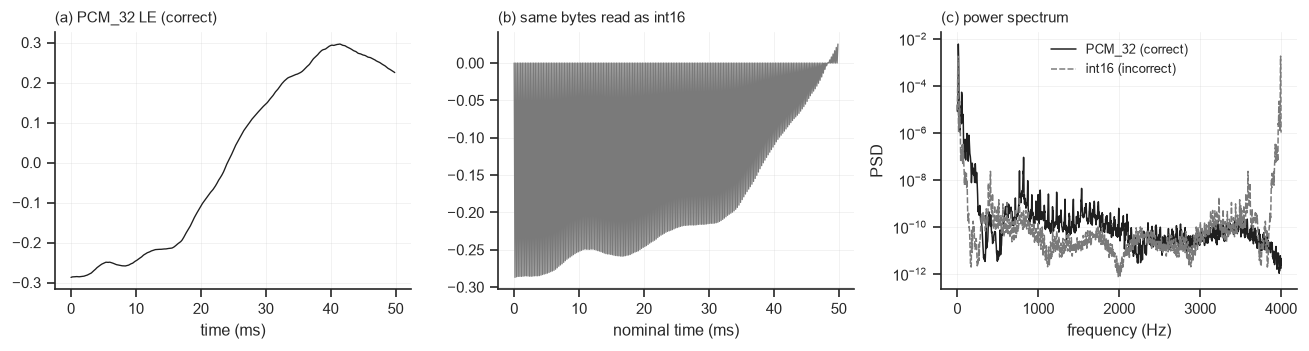

In [6]:
import seaborn as sns
x16, _ = io_utils.load_d3_raw(probe, decoding="int16_legacy")
cfg.apply_mpl_style()
G = cfg.GREYS
n_show = 400
fig, ax = plt.subplots(1, 3, figsize=(11, 3.0))
sns.lineplot(x=np.arange(n_show) / fs * 1000, y=x32[:n_show], color=G[5], linewidth=0.8, ax=ax[0])
ax[0].set_title("(a) PCM_32 LE (correct)", loc="left", fontsize=9); ax[0].set_xlabel("time (ms)")
sns.lineplot(x=np.arange(n_show) / fs * 1000, y=x16[:n_show], color=G[3], linewidth=0.8, ax=ax[1])
ax[1].set_title("(b) same bytes read as int16", loc="left", fontsize=9); ax[1].set_xlabel("nominal time (ms)")
psd = []
for x, lab in [(x32, "PCM_32 (correct)"), (x16[:2 * cfg.CLIP_SAMPLES], "int16 (incorrect)")]:
    f, P = signal.welch(x, fs=fs, nperseg=4096)
    psd.append(pd.DataFrame(dict(freq=f, psd=P, decoding=lab)))
sns.lineplot(data=pd.concat(psd), x="freq", y="psd", hue="decoding", style="decoding",
             palette=[G[5], G[3]], linewidth=0.9, ax=ax[2])
ax[2].set_yscale("log"); ax[2].set_xlabel("frequency (Hz)"); ax[2].set_ylabel("PSD")
ax[2].set_title("(c) power spectrum", loc="left", fontsize=9); ax[2].legend(fontsize=7.5, title=None)
for a in ax:
    sns.despine(ax=a)
fig.tight_layout()
cfg.save_figure(fig, "FigA4_D3_decoding_check")
plt.show()

## 5. Verdict

Pass criteria: file size divisible by 4, no header, reader = numpy int32 LE, lag-1 autocorrelation int32 LE > int16

In [7]:
e = evd[~raws.is_bg.values]
verdict = dict(
    n_files=int(len(evd)),
    all_sizes_divisible_by_4=bool((evd.size_mod_4 == 0).all()),
    any_header=bool(evd.has_riff_or_aiff_header.any()),
    max_printable_fraction=float(evd.printable_fraction_first_4k.max()),
    samples_if_int32=sorted(evd.samples_if_int32.unique().tolist()),
    seconds_if_int32_at_8k=sorted(evd.seconds_if_int32_at_8k.round(3).unique().tolist()),
    median_frac_zero_low16=float(evd.frac_int32_words_with_zero_low16.median()),
    median_lag1_int32_le=float(evd.lag1_autocorr_int32_le.median()),
    median_lag1_int32_be=float(evd.lag1_autocorr_int32_be.median()),
    median_lag1_int16=float(evd.lag1_autocorr_int16_le.median()),
    provider_script=script, reader=reader, synthetic_tone=syn,
    conclusion=("binary 32-bit little-endian PCM, mono; 8 kHz per the provider; "
                "first 240,000 samples kept and the remainder discarded as the "
                "provider's script does (df.head(240000))"),
)
for k, v in verdict.items():
    print(f"  {k:28s} {v}")
la.save_json(verdict, "D3_raw_format_check.json")
rp.record("D3.raw.samples_if_int32", float(np.median(evd.samples_if_int32)), "D3_raw_format_check.json", "R1-M12,R2-14")
rp.record("D3.raw.frac_zero_low16", verdict["median_frac_zero_low16"], "D3_raw_format_check.json", "R1-M12,R2-14")
rp.record("D3.raw.synthetic_440Hz_read_as_int16_peak", syn["peaks_int16_reading"][0],
          "D3_raw_format_check.json", "R1-M12,R2-14")
ok = (verdict["all_sizes_divisible_by_4"] and not verdict["any_header"]
      and reader["matches_numpy_int32"] and verdict["median_lag1_int32_le"] > verdict["median_lag1_int16"])
print("\nRESOLVED - PCM_32 little-endian confirmed" if ok else "\nCHECK FAILED - inspect the table above")

  n_files                      122
  all_sizes_divisible_by_4     True
  any_header                   False
  max_printable_fraction       0.22509765625
  samples_if_int32             [279460, 285960, 286960, 287960, 288460, 288710, 289460, 289960, 290210, 290460, 291210, 291460, 291710, 291960, 292210, 292460, 292960, 294960, 295210, 295710, 295960, 296460, 298460, 298960, 299210, 299460, 300960, 302710, 304210, 304710, 306710, 307460, 311710, 314710, 318710, 320460, 321460, 324960, 330460, 331210, 334210, 334960, 345960, 349210, 369460, 407210, 415710, 490460]
  seconds_if_int32_at_8k       [34.932, 35.745, 35.87, 35.995, 36.058, 36.089, 36.182, 36.245, 36.276, 36.308, 36.401, 36.432, 36.464, 36.495, 36.526, 36.558, 36.62, 36.87, 36.901, 36.964, 36.995, 37.058, 37.308, 37.37, 37.401, 37.432, 37.62, 37.839, 38.026, 38.089, 38.339, 38.432, 38.964, 39.339, 39.839, 40.058, 40.182, 40.62, 41.308, 41.401, 41.776, 41.87, 43.245, 43.651, 46.182, 50.901, 51.964, 61.308]
  median_frac_zero_low